#### `Notebook Number:- 4`
#### We are doing pre processing on the Transaction_risk_insights_feature_engineered.csv
-  In the Feature_Engineering.ipynb(which is our last notebook)
-  we created new features and save it on a new dataset `Transaction_risk_insights_feature_engineered.csv`
-  so in this notebook we are doing pre processing the Transaction_risk_insights_feature_engineered.csv
-  so that we make our features ready for the ML part


In [25]:
# we will jsut add the require lobraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [26]:
# Now we will load the datastet where we created new features and we will do the preprocessing on it
df = pd.read_csv(r"../Datasets/Transaction_risk_insights_feature_engineered.csv")
df["transaction_date"] = pd.to_datetime(df["transaction_date"],errors="coerce")
df["transaction_time"] = pd.to_datetime(df["transaction_time"],errors="coerce")

df.sample(10)

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,...,transaction_year,transaction_month,transaction_day,day_of_week,is_weekend,time_period,transaction_amount_category,balance_category,credit_score_category,customer_transaction_count
433003,TXN000433004,CUST061713,2022-12-08,1900-01-01 01:42:00,Current,UPI,4390.07,Credit,26602.34,Education,...,2022,12,8,Thursday,0,Night,Low,Medium,Low,9
183267,TXN000183268,CUST019764,2020-08-31,1900-01-01 15:36:00,NRI,NEFT,1876.14,Debit,34428.89,Peer Transfer,...,2020,8,31,Monday,0,Afternoon,Low,Medium,Medium,9
367973,TXN000367974,CUST000353,2022-05-08,1900-01-01 05:14:00,Current,ATM_Withdrawal,1000.00,Debit,111084.32,Healthcare,...,2022,5,8,Sunday,1,Night,Low,High,Medium,16
205080,TXN000205081,CUST077440,2020-11-12,1900-01-01 23:10:00,Salary,UPI,3428.26,Credit,494486.92,Food & Dining,...,2020,11,12,Thursday,0,Evening,Low,High,Medium,5
263443,TXN000263444,CUST027518,2021-05-25,1900-01-01 21:28:00,Savings,RTGS,105162.35,Credit,267486.63,Education,...,2021,5,25,Tuesday,0,Evening,High,High,Medium,8
427091,TXN000427092,CUST047508,2022-11-18,1900-01-01 15:10:00,Savings,UPI,734.99,Credit,375069.52,Government,...,2022,11,18,Friday,0,Afternoon,Low,High,Medium,9
395442,TXN000395443,CUST064792,2022-08-06,1900-01-01 04:41:00,Savings,Net_Banking,6213.12,Debit,241692.81,Government,...,2022,8,6,Saturday,1,Night,Low,High,Medium,9
129029,TXN000129030,CUST017929,2020-03-04,1900-01-01 07:52:00,NRI,UPI,869.83,Debit,348911.92,Food & Dining,...,2020,3,4,Wednesday,0,Morning,Low,High,Medium,10
435829,TXN000435830,CUST056904,2022-12-17,1900-01-01 00:30:00,Current,ATM_Withdrawal,500.00,Debit,64441.82,Food & Dining,...,2022,12,17,Saturday,1,Night,Low,Medium,Medium,11
373024,TXN000373025,CUST010342,2022-05-24,1900-01-01 21:33:00,Current,IMPS,1568.02,Debit,20593.21,Investment,...,2022,5,24,Tuesday,0,Evening,Low,Low,Medium,6


In [27]:
# Now we will check dataset shape and information
print("Dataset Shape:", df.shape)
print("\nDataset Information:")
df.info()

Dataset Shape: (550000, 30)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550000 entries, 0 to 549999
Data columns (total 30 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   transaction_id               550000 non-null  object        
 1   customer_id                  550000 non-null  object        
 2   transaction_date             550000 non-null  datetime64[ns]
 3   transaction_time             550000 non-null  datetime64[ns]
 4   account_type                 550000 non-null  object        
 5   transaction_type             550000 non-null  object        
 6   transaction_amount           550000 non-null  float64       
 7   transaction_direction        550000 non-null  object        
 8   account_balance              550000 non-null  float64       
 9   merchant_category            550000 non-null  object        
 10  state                        550000 non-nu

In [28]:
# now we will check the fraud distrubution in the dataset
print(df["is_fraud"].value_counts())
print("\nFraud Percentage:")
print((df["is_fraud"].value_counts(normalize=True) * 100).round(2))


is_fraud
0    545127
1      4873
Name: count, dtype: int64

Fraud Percentage:
is_fraud
0    99.11
1     0.89
Name: proportion, dtype: float64


#### `1:-` Now we will checking numerical feature distribution and and also doing skewness analysis

In [29]:
numerical_cols = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# removing target variable
numerical_cols.remove("is_fraud")
# checking for skewness in the numerical columns
skewness = df[numerical_cols].skew().sort_values(
    ascending=False
)

print(skewness)

transaction_amount            18.813860
account_balance                9.320360
emi_amount                     4.341817
is_weekend                     0.946211
has_loan                       0.630749
customer_transaction_count     0.370120
transaction_day                0.008118
transaction_year               0.001443
transaction_hour               0.000283
credit_score                  -0.001503
transaction_month             -0.013256
dtype: float64


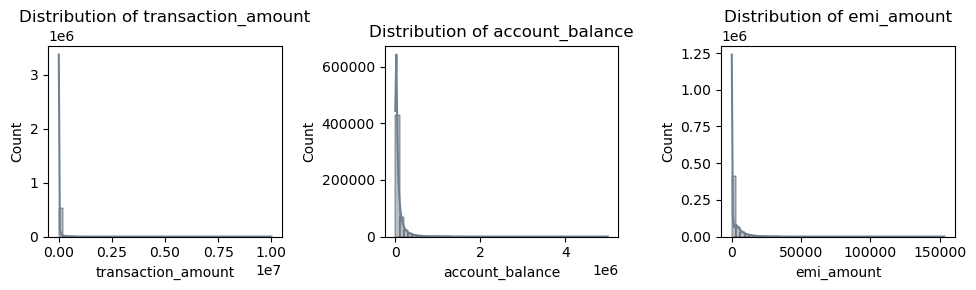

In [30]:
# just ploting the transaction_amount,account_balance,emi_amount
# beacuse these columns are highly skewed.
skewed_features = [
    "transaction_amount",
    "account_balance",
    "emi_amount"
]

fig, axes = plt.subplots(1, 3, figsize=(10, 3))

for i, col in enumerate(skewed_features):
    sns.histplot(
        data=df,
        x=col,
        bins=50,
        ax=axes[i],
        color='slategray',
        kde=True
    )

    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

### Numerical Feature Skewness Analysis
- **transaction_amount (18.81):** is highly right-skewed, indicating that most transactions have relatively small amounts, while a few transactions have extremely large amounts.
- **account_balance (9.32):** is also highly right-skewed, indicating that most account balances are concentrated at lower values, with a few very large balances.
- **emi_amount (4.34):** is also positively skewed, indicating that most EMI amounts are relatively small, while fewer records have larger EMI values.

The remaining numerical features have comparatively low skewness. Features such as transaction_hour, transaction_year, transaction_day, and credit_score have distributions that are approximately symmetric.

The histogram visualizations further confirmed the right-skewed distributions of transaction_amount, account_balance, and emi_amount.


#### `2:-` Now we will do the log transfrom

In [31]:
# now we will create a copy of the original dataframe
df_transformed = df.copy()

# Applying the  log transformation
skewed_features = [
    "transaction_amount",
    "account_balance",
    "emi_amount"
]

for col in skewed_features:
    df_transformed[col + "_log"] = np.log1p(df_transformed[col])

In [32]:
# now we will check the skewness after log transformation
for col in skewed_features:
    print(f"\n{col}")
    print("Original Skewness:", df[col].skew())
    print("Transformed Skewness:",
          df_transformed[col + "_log"].skew())


transaction_amount
Original Skewness: 18.81385962152366
Transformed Skewness: 0.654037219440166

account_balance
Original Skewness: 9.320359760467014
Transformed Skewness: 0.0014089851403345263

emi_amount
Original Skewness: 4.341817406197147
Transformed Skewness: 0.6726358102046774


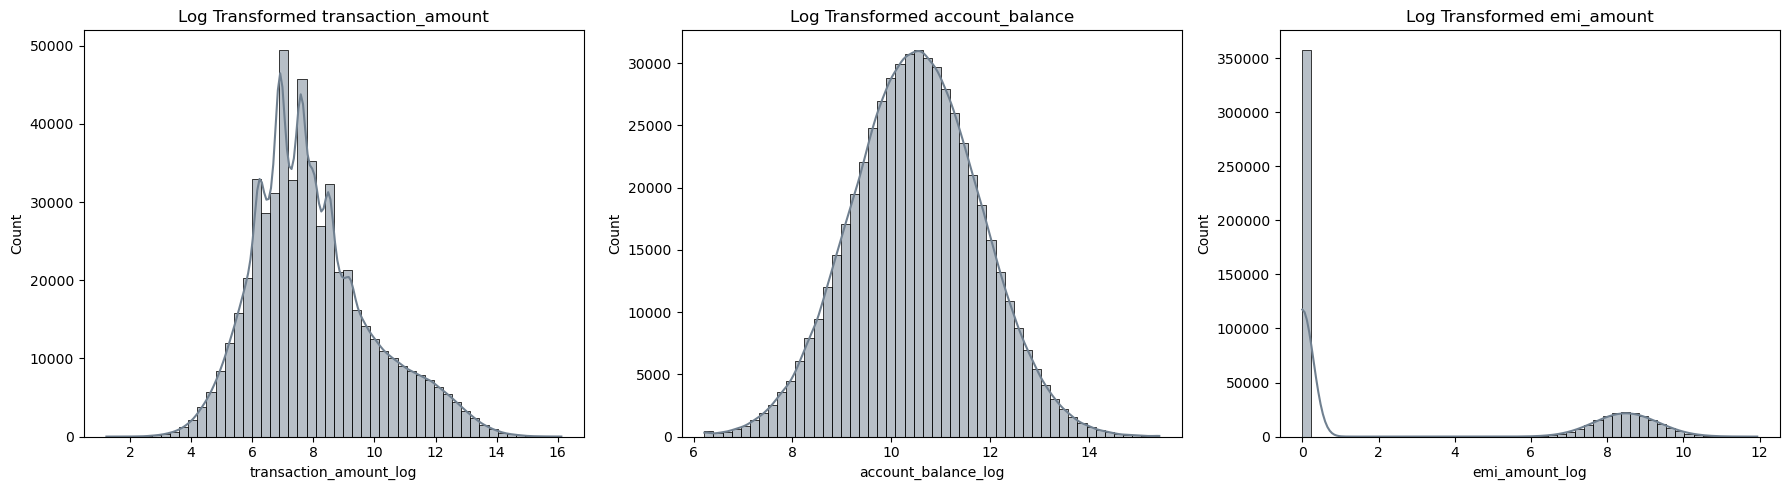

In [33]:
# Now we will plot the log transformed features
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(skewed_features):
    sns.histplot(
        data=df_transformed,
        x=col + "_log",
        bins=50,
        ax=axes[i],
        color='slategray',
        kde=True
    )

    axes[i].set_title(f"Log Transformed {col}")

plt.tight_layout()
plt.show()

#### Log-Transformed

Histograms were plotted to examine the distributions of the three log-transformed numerical features.

The following observations were made:

1. **Transaction Amount:** The distribution became considerably less right-skewed after log transformation, although some positive skewness remains.

2. **Account Balance:** The transformed distribution became approximately symmetric and resembles a bell-shaped distribution.

3. **EMI Amount:** The transformed distribution shows two noticeable groups, with a large concentration near zero and another group around higher values. This may be related to transactions associated with customers who do not have EMI payments.

**Conclusion:**

Log transformation significantly improved the distributions of the selected numerical features. However, the EMI amount distribution requires further investigation because of its concentration near zero and its separate positive-value group.

#### `3:-` Now we will do further investigation on emi_amount_log 

In [34]:
# now we will check the zero and positive EMI amounts in the dataset
print("Zero EMI Amounts:", (df["emi_amount"] == 0).sum())

print("Positive EMI Amounts:", (df["emi_amount"] > 0).sum())

print(
    "Zero EMI Percentage:",
    round((df["emi_amount"] == 0).mean() * 100, 2), "%"
)

Zero EMI Amounts: 357712
Positive EMI Amounts: 192288
Zero EMI Percentage: 65.04 %


In [35]:
# now we will compare EMI with the loan status(has_loan column)
pd.crosstab(
    df["has_loan"],
    df["emi_amount"] == 0,
    normalize="index"
).round(3) * 100

emi_amount,False,True
has_loan,,
0,0.0,100.0
1,100.0,0.0


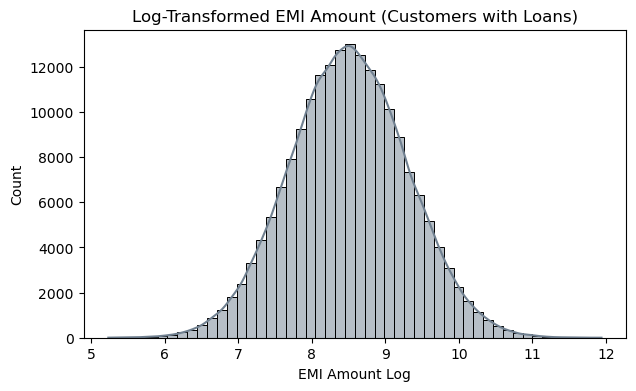

In [36]:
# now we will check EMi distribution for customers with
fig, axes = plt.subplots(figsize=(7, 4))
sns.histplot(
    data=df_transformed[df_transformed["has_loan"] == 1],
    x="emi_amount_log",
    bins=50,
    kde=True,
    color='slategray'
)

plt.title("Log-Transformed EMI Amount (Customers with Loans)")
plt.xlabel("EMI Amount Log")
plt.show()

#### EMI Amount Distribution Analysis
- 357,712 records (65.04%) have zero EMI amounts.
- 192,288 records (34.96%) have positive EMI amounts.
- All customers without loans have zero EMI amounts.
- All customers with loans have positive EMI amounts.

After filtering the dataset to include only customers with loans, the log-transformed EMI distribution appeared approximately bell-shaped.

**Conclusion:**

The unusual overall EMI distribution is mainly associated with the presence of two distinct groups: customers without loans and customers with loans.

The EMI amount feature will be retained because it provides additional information about the customer's financial commitments. The has_loan feature will also be retained to represent loan status.

#### `4:-` Now we will finalize our feature list for the ML part

In [37]:
features = [
    "account_type",
    "transaction_type",
    "transaction_amount_log",
    "transaction_direction",
    "account_balance_log",
    "merchant_category",
    "state",
    "credit_score",
    "has_loan",
    "loan_type",
    "emi_amount_log",
    "channel",
    "kyc_status",
    "transaction_hour",
    "transaction_month",
    "day_of_week",
    "is_weekend"
]

In [38]:
# now we will create the feature matrix X and target vector y
X = df_transformed[features]

y = df_transformed["is_fraud"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (550000, 17)
Target Shape: (550000,)


In [39]:
# Now we divide the data into train and test set
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (440000, 17)
X_test: (110000, 17)
y_train: (440000,)
y_test: (110000,)


In [40]:
# Now we will identify numerical columns
numerical_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

print("\nTotal Numerical Columns:", len(numerical_cols))
print("Total Categorical Columns:", len(categorical_cols))

Numerical Columns:
['transaction_amount_log', 'account_balance_log', 'credit_score', 'has_loan', 'emi_amount_log', 'transaction_hour', 'transaction_month', 'is_weekend']

Categorical Columns:
['account_type', 'transaction_type', 'transaction_direction', 'merchant_category', 'state', 'loan_type', 'channel', 'kyc_status', 'day_of_week']

Total Numerical Columns: 8
Total Categorical Columns: 9


#### `5:-` Now we will do numerical scaling and categorical Encoding.

In [41]:
# just importing the required libraries for preprocessing
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [42]:
# Now we will create a preprocessing pipeline for numerical and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)


In [43]:
# Fit the preprocessing pipeline on training data
X_train_processed = preprocessor.fit_transform(X_train)

print("Original Training Shape:", X_train.shape)
print("Processed Training Shape:", X_train_processed.shape)

Original Training Shape: (440000, 17)
Processed Training Shape: (440000, 74)


In [44]:
# Now we will transform testing data using the already fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("Original Testing Shape:", X_test.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Original Testing Shape: (110000, 17)
Processed Testing Shape: (110000, 74)


In [45]:
# now we once verify the processed data
print("Training Data:")
print("Shape:", X_train_processed.shape)
print("Missing Values:", np.isnan(X_train_processed.data).sum())

print("\nTesting Data:")
print("Shape:", X_test_processed.shape)
print("Missing Values:", np.isnan(X_test_processed.data).sum())

Training Data:
Shape: (440000, 74)
Missing Values: 0

Testing Data:
Shape: (110000, 74)
Missing Values: 0


#### Observation

The preprocessing of the dataset was completed using `ColumnTransformer`.

- Numerical features were scaled using `StandardScaler`.
- Categorical features were encoded using `OneHotEncoder`.
- The original 17 input features were transformed into 74 features.
- The training dataset contains 440,000 records.
- The testing dataset contains 110,000 records.
- No missing values were found in either processed dataset.

The same preprocessing transformations were applied to both training and testing data to prevent data leakage.

In [46]:
# now we will save the output
import joblib
import os

In [47]:
# creating a new file to save the processed data
os.makedirs("../Processed_Data", exist_ok=True)

In [ ]:
# Now we will save the processed training and testing features
joblib.dump(X_train_processed, "../Processed_Data/X_train_processed.pkl")
joblib.dump(X_test_processed, "../Processed_Data/X_test_processed.pkl")

# also we will save target variables
joblib.dump(y_train, "../Processed_Data/y_train.pkl")
joblib.dump(y_test, "../Processed_Data/y_test.pkl")

# Saving preprocessing object
joblib.dump(preprocessor, "../Processed_Data/preprocessor.pkl")

print("All preprocessing files saved successfully")

All preprocessing files saved successfully
